# P8 / 01: OU-optimal entry and exit rules on the S05 residual (both windows)

Protocol: [`001_claude_p8_ou_optimal_thresholds_preregistration.md`](../../discussions/OU_Optimal_Thresholds/001_claude_p8_ou_optimal_thresholds_preregistration.md).

- **`BT` (Bertram):** a symmetric band ±m* per stock and day, maximising net s-units per unit time given the round-trip cost in σ units.
- **`LP` (Lipton & López de Prado):** entry at |s| ≥ 1.25; per-trade take-profit, stop-loss and a 3-half-life limit, chosen from a simulated first-passage table.
- **Incumbent:** S05 with `x10` exits and the earnings filter (P4 `EX`).
- **Common to all:** measured costs, and no entries inside earnings windows.

**Gates** per window and arm (α = 0.05/2):
- **G1** net bootstrap lower bound > 0;
- **G2** net minus incumbent net, paired bootstrap lower bound > 0;
- **G3** net > 0 at 2× cost.

In [1]:
import json, os, sys, time
from dataclasses import replace
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import __version__, p1, p2, p4, p8, s04, s05, s05b
from equity_trading.alpaca import ALPACA_VERSION
from equity_trading.data import vendor_dir, work_dir

SYNTHETIC = os.environ.get("P8_SYNTHETIC") == "1"
REQUIRED = {"p8": "0.1.0", "s05": "0.1.3"}
_have = {"p8": p8.P8_VERSION, "s05": s05.S05_VERSION}
assert _have == REQUIRED, f"stale equity_trading modules {_have}, expected {REQUIRED}: restart the kernel and run again"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.titleweight": "bold", "font.size": 9})
PC = p8.P8Config()
SCFG = s05.S05Config(close_long=1.0, close_short=-1.0)               # incumbent x10 exits; estimation as S05
YEARS = {"A 2020-2025": list(range(2020, 2026)), "B 2017-2019": [2017, 2018, 2019]}   # 2026 sealed
QUOTE_CACHE = vendor_dir("Alpaca") / "quote_samples" / "15Min_w3s"
PANEL_B = work_dir() / "results" / "p3" / "panel_15Min_2017_2019.npz"
OUT = ROOT / "notebooks" / "OU_Optimal_Thresholds" / ("01_synthetic" if SYNTHETIC else "01")
OUT.mkdir(parents=True, exist_ok=True)
CACHE = work_dir() / "results" / ("p8_synthetic" if SYNTHETIC else "p8") / f"v{p8.P8_VERSION}"
CACHE.mkdir(parents=True, exist_ok=True)
if SYNTHETIC:
    YEARS = {"A 2025": [2025], "B 2024": [2024]}
    PC = replace(PC, sim_paths=500, n_boot=2000)
    from equity_trading.universe import SECTOR_ETF_01, UNIVERSE_01
    ETF_OF = {s: SECTOR_ETF_01[k] for k, v in UNIVERSE_01.items() for s in v}
    EVENTS = None
else:
    constituents = pd.read_csv(ROOT / "src" / "equity_trading" / "reference" / "sp500_constituents_20260913.csv")
    ETF_OF = dict(zip(constituents["Symbol"], constituents["GICS Sector"].map(s05.SECTOR_ETF)))
    EVENTS = p4.edgar_earnings(sorted(ETF_OF), start="2016-01-01", end="2025-12-31", verbose=False)
STOCKS, ETFS = sorted(ETF_OF), sorted(set(ETF_OF.values()))
print(f"synthetic={SYNTHETIC} | versions {_have}")

synthetic=False | versions {'p8': '0.1.0', 's05': '0.1.3'}


## 1. The two rules in s units: Bertram's m*(c) and the LP first-passage table

In [2]:
t0 = time.time()
BT_TAB = p8.bertram_table(PC.c_grid)
lp_path = CACHE / "lp_table.npz"
if lp_path.exists():
    TAB = dict(np.load(lp_path))
else:
    TAB = p8.lp_table(PC); np.savez(lp_path, **TAB)
LP_CH = p8.lp_choice(TAB, PC.c_grid)
print(f"tables in {time.time() - t0:.0f}s")
show_c = [0.05, 0.1, 0.2, 0.5, 1.0, 2.0]
ci = p8.lookup(np.array(PC.c_grid), np.array(show_c))
display(pd.DataFrame({"c (round trip, sigma units)": show_c, "Bertram m*": BT_TAB.to_numpy()[ci].round(3)}).set_index("c (round trip, sigma units)").T)
lp_view = {}
for c_, i in zip(show_c, ci):
    for s0 in (1.25, 2.0, 3.0, 4.0):
        j = int(np.argmin(np.abs(LP_CH["s0"] - s0)))
        lp_view[(c_, s0)] = {"take_profit": LP_CH["tp"][i, j], "stop_beyond_entry": LP_CH["sl"][i, j], "rate": round(float(LP_CH["rate"][i, j]), 3)}
display(pd.DataFrame(lp_view).T.rename_axis(["c", "|s0|"]))

tables in 3s


"c (round trip, sigma units)",0.05,0.10,0.20,0.50,1.00,2.00
Bertram m*,0.427,0.549,0.674,0.978,1.228,1.687


take_profit  stop_beyond_entry   rate
c    |s0|                                       
0.05 1.25         -1.0                inf  1.356
     2.00         -1.0                inf  1.772
     3.00         -1.0                inf  2.171
     4.00         -1.0                2.0  2.528
0.10 1.25         -0.5                inf  1.191
     2.00         -1.0                inf  1.679
     3.00         -1.0                inf  2.112
     4.00         -1.0                2.0  2.482
0.20 1.25         -0.5                inf  1.049
     2.00         -1.0                inf  1.535
     3.00         -1.0                inf  2.022
     4.00         -1.0                2.0  2.411
0.50 1.25          0.0                inf  0.621
     2.00         -0.5                inf  1.056
     3.00         -1.0                inf  1.660
     4.00         -1.0                2.0  2.127
1.00 1.25          0.5                inf  0.266
     2.00          0.0                inf  0.664
     3.00         -0.5                inf  1.213
     4.00         -1.0                2.0  1.774
2.00 1.25          1.0                inf -0.351
     2.00          0.5                inf -0.003
     3.00          0.0                inf  0.470
     4.00         -0.5                2.0  0.972

## 2. Per window: data, cost in σ units, incumbent, BT, LP

A 2020-2025: panel (39064, 513), traded 501, data ready in 87s


,count,mean,std,min,10%,25%,50%,75%,90%,max
c_sigma,719594.0,0.0617,0.0487,0.0012,0.0184,0.0293,0.0485,0.0784,0.1202,0.8438
bertram_m_star,719594.0,0.4342,0.1083,0.2476,0.3015,0.3498,0.4267,0.4960,0.5774,1.1584


9 backtests in 2.6 min


,total_return,sharpe,max_drawdown,mean_daily,days
incumbent 1x,0.2141,0.6554,0.0827,0.0001,1486.0
BT 1x,0.1799,0.5484,0.0867,0.0001,1486.0
LP 1x,-0.5231,-2.0606,0.5268,-0.0005,1486.0
incumbent 2x,-0.0045,0.0309,0.1154,0.0000,1486.0
BT 2x,-0.0962,-0.2662,0.1648,-0.0001,1486.0
LP 2x,-0.8204,-5.1567,0.8192,-0.0011,1486.0
incumbent 0x,0.4962,1.3078,0.0691,0.0003,1486.0
BT 0x,0.5800,1.4257,0.0767,0.0003,1486.0
LP 0x,0.6818,1.4529,0.0717,0.0004,1486.0


,trades,trades_per_day,median_bars,gross_per_trade_bps,cost_per_trade_bps,exit_rule,exit_invalid,exit_end,exit_take_profit,exit_time_limit,exit_stop_loss
incumbent,16936.0,11.389,208.0,25.884,13.134,0.956,0.038,0.006,NaN,NaN,NaN
BT,22871.0,15.381,143.0,21.562,13.167,NaN,0.034,0.004,0.962,NaN,NaN
LP,104916.0,70.555,26.0,5.237,12.504,NaN,0.010,0.001,0.899,0.081,0.009


,BT,LP
G1_edge,False,False
G2_improvement,False,False
G3_double_cost,False,False


,incumbent,BT,LP
2020,9.59,9.17,-5.47
2021,-0.78,-1.53,-12.51
2022,2.43,3.85,-12.42
2023,2.01,2.62,-9.46
2024,4.43,3.68,-11.58
2025,2.85,-0.15,-17.31


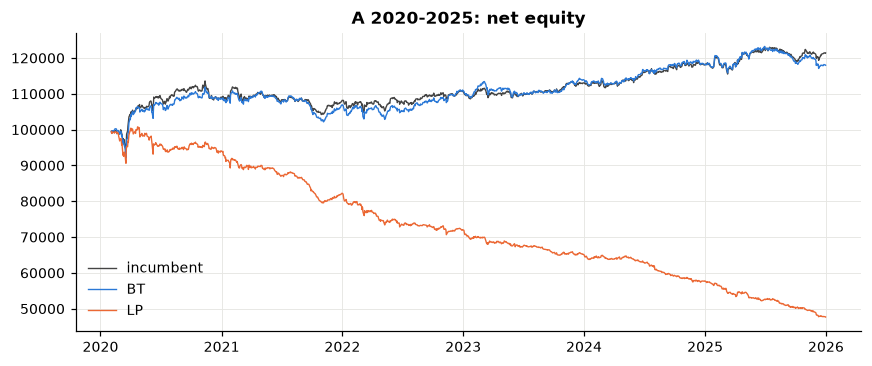

B 2017-2019: panel (19508, 492), traded 480, data ready in 46s


,count,mean,std,min,10%,25%,50%,75%,90%,max
c_sigma,331390.0,0.0624,0.0456,0.0014,0.0214,0.0320,0.0504,0.0794,0.1173,0.8425
bertram_m_star,331390.0,0.4394,0.1007,0.2476,0.3168,0.3675,0.4267,0.4960,0.5774,1.1584


9 backtests in 1.4 min


,total_return,sharpe,max_drawdown,mean_daily,days
incumbent 1x,-0.0100,-0.1082,0.0471,-0.0000,732.0
BT 1x,-0.0377,-0.4151,0.0654,-0.0001,732.0
LP 1x,-0.2609,-2.9589,0.2659,-0.0004,732.0
incumbent 2x,-0.0867,-1.0257,0.1085,-0.0001,732.0
BT 2x,-0.1366,-1.6172,0.1451,-0.0002,732.0
LP 2x,-0.5536,-8.2538,0.5543,-0.0011,732.0
incumbent 0x,0.0767,0.8328,0.0415,0.0001,732.0
BT 0x,0.0730,0.7707,0.0431,0.0001,732.0
LP 0x,0.2476,2.0870,0.0445,0.0003,732.0


,trades,trades_per_day,median_bars,gross_per_trade_bps,cost_per_trade_bps,exit_rule,exit_invalid,exit_end,exit_take_profit,exit_time_limit,exit_stop_loss
incumbent,8332.0,11.367,207.0,8.868,10.129,0.954,0.035,0.011,NaN,NaN,NaN
BT,11349.0,15.483,142.0,6.630,10.028,NaN,0.029,0.008,0.962,NaN,NaN
LP,55141.0,75.226,26.0,4.193,9.935,NaN,0.008,0.001,0.903,0.081,0.007


,BT,LP
G1_edge,False,False
G2_improvement,False,False
G3_double_cost,False,False


,incumbent,BT,LP
2017,-1.85,-1.67,-10.20
2018,1.45,0.36,-7.46
2019,-0.66,-2.56,-11.19


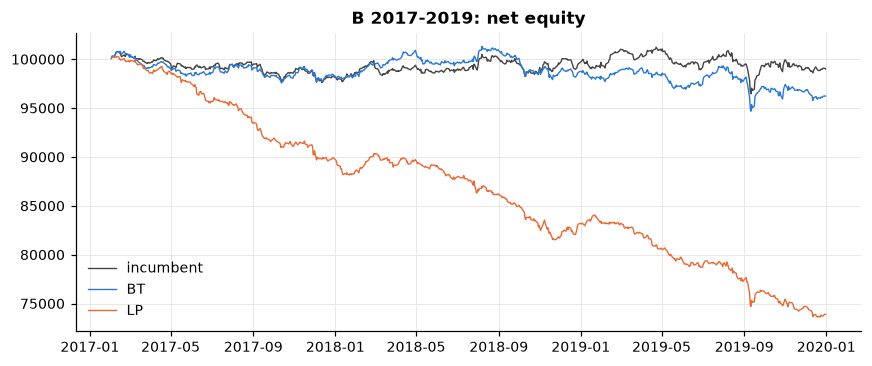

In [3]:
RESULTS = {}
for wi, (wname, years) in enumerate(YEARS.items()):
    w = wname.split()[0]
    t0 = time.time()
    if SYNTHETIC:
        panel, _ = s04.synthetic_ohlc_panel(years, seed=3 + wi)
        H = np.full(panel.c.shape, 2e-4, np.float32)
    else:
        panel = (s04.cached_panel(STOCKS + ETFS + ["SPY"], "15Min", years) if w == "A"
                 else p2.panel_cache(STOCKS + ETFS + ["SPY"], "15Min", years, PANEL_B))
        sess = s05b.sample_sessions(years, 4, seed=42)
        samples = pd.concat([pd.read_parquet(QUOTE_CACHE / f"{d}.parquet") for d in sess], ignore_index=True)
        H = s05b.cost_array(panel.index, panel.day_start, panel.symbols, s05b.cost_model(samples))
    have = set(panel.symbols)
    TRADED = [s for s in STOCKS if s in have and ETF_OF[s] in have]
    SC = np.array([panel.symbols.index(s) for s in TRADED]); EC = np.array([panel.symbols.index(ETF_OF[s]) for s in TRADED])
    tag = ("synthetic_" if SYNTHETIC else "") + f"{w}_s05{s05.S05_VERSION}_p{s04.PANEL_VERSION}"
    est_path = CACHE / f"params_{tag}.npz"
    P = dict(np.load(est_path)) if est_path.exists() else s05.estimate_all(panel, SC, EC, SCFG, s05.first_decision_day(SCFG))
    if not est_path.exists():
        np.savez(est_path, **P)
    days = pd.DatetimeIndex(pd.to_datetime(list(panel.days)))
    ev = p4.synthetic_events(days, TRADED, seed=11 + wi) if SYNTHETIC else EVENTS
    EF = p4.event_flags(ev, days, TRADED, 1, 1).to_numpy()
    MASK = ~np.vstack([EF[1:], np.zeros((1, len(TRADED)), bool)])          # P4 EX: no entries on sessions in windows
    CT = p8.cost_sigma_units(P, H, panel, SC, EC)
    v = P["valid"].astype(bool) & np.isfinite(CT)
    mstar = BT_TAB.to_numpy()[p8.lookup(BT_TAB.index.to_numpy(), np.where(v, CT, 1.0))][v]
    dist = pd.DataFrame({"c_sigma": CT[v], "bertram_m_star": mstar}).describe(percentiles=[.1, .25, .5, .75, .9]).T
    print(f"{wname}: panel {panel.c.shape}, traded {len(TRADED)}, data ready in {time.time() - t0:.0f}s", flush=True)
    display(dist.round(4))
    runs = {}
    t0 = time.time()
    for cm in (1.0, 2.0, 0.0):
        runs[("incumbent", cm)] = s05.backtest(panel, P, SC, EC, replace(SCFG, cost_mult=cm), record=(cm == 1.0), half_spread=H, entry_mask=MASK)
        runs[("BT", cm)] = p8.backtest(panel, P, SC, EC, SCFG, "BT", H, CT, PC, bt_tab=BT_TAB, entry_mask=MASK, cost_mult=cm, record=(cm == 1.0))
        runs[("LP", cm)] = p8.backtest(panel, P, SC, EC, SCFG, "LP", H, CT, PC, lp_ch=LP_CH, entry_mask=MASK, cost_mult=cm, record=(cm == 1.0))
    START = runs[("incumbent", 1.0)]["first_day"]
    print(f"{len(runs)} backtests in {(time.time() - t0) / 60:.1f} min", flush=True)
    METRICS = pd.DataFrame({f"{a} {cm:g}x": s04.perf_metrics(r["daily_equity"], SCFG.initial_equity, START) for (a, cm), r in runs.items()}).T
    TS = {}
    for a in ("incumbent", "BT", "LP"):
        tr, r = runs[(a, 1.0)]["trades"], runs[(a, 1.0)]
        TS[a] = {"trades": len(tr), "trades_per_day": len(tr) / max(len(r["daily_equity"][r["daily_equity"].index >= START]), 1),
                 "median_bars": float(tr.bars.median()) if len(tr) else np.nan,
                 "gross_per_trade_bps": 1e4 * tr.gross_ret.mean() if len(tr) else np.nan,
                 "cost_per_trade_bps": 1e4 * r["total_cost"] / tr.notional.sum() if len(tr) else np.nan,
                 **({f"exit_{k}": float(x) for k, x in tr["reason"].value_counts(normalize=True).items()} if len(tr) else {})}
    TS = pd.DataFrame(TS).T
    daily = {a: runs[(a, 1.0)]["daily_equity"].pipe(lambda e: e[e.index >= START].pct_change().dropna()) for a in ("incumbent", "BT", "LP")}
    G = {}
    for a in ("BT", "LP"):
        bn = {b: p1.block_bootstrap(daily[a].to_numpy(), b, PC.n_boot, PC.seed, PC.alpha) for b in PC.blocks}
        bd = {b: p8.paired_bootstrap(daily[a], daily["incumbent"], b, PC.n_boot, PC.seed, PC.alpha) for b in PC.blocks}
        G[a] = {**p8.gates(bn, bd, METRICS.loc[f"{a} 2x"].to_dict()),
                "boot_net_bps": {str(b): [1e4 * x for x in q] for b, q in bn.items()},
                "boot_diff_bps": {str(b): [1e4 * x for x in q] for b, q in bd.items()}}
    YR = pd.DataFrame({a: d.groupby(d.index.year).apply(lambda x: (1 + x).prod() - 1) for a, d in daily.items()})
    display(METRICS.round(4)); display(TS.round(3))
    display(pd.DataFrame({a: {k: v for k, v in g.items() if not k.startswith("boot")} for a, g in G.items()}))
    display((100 * YR).round(2))
    for a in ("incumbent", "BT", "LP"):
        runs[(a, 1.0)]["daily_equity"].to_csv(OUT / f"daily_equity_{w}_{a}.csv", header=["equity"], float_format="%.2f")
    RESULTS[wname] = {"metrics": METRICS.to_dict(orient="index"), "trade_stats": TS.to_dict(orient="index"), "gates": G,
                      "net_by_year": {str(k): x for k, x in YR.to_dict(orient="index").items()}, "cost_and_mstar": dist.to_dict(orient="index")}
    fig, ax = plt.subplots(figsize=(8, 3.4))
    for a, col in zip(("incumbent", "BT", "LP"), ("#444444", "#2a78d6", "#eb6834")):
        e = runs[(a, 1.0)]["daily_equity"]; e = e[e.index >= START]
        ax.plot(e.index, e, color=col, lw=0.9, label=a)
    ax.set_title(f"{wname}: net equity"); ax.legend(frameon=False); plt.tight_layout(); plt.show()
    del panel, H, P, runs

## 3. Verdicts

In [4]:
V = {}
for a in ("BT", "LP"):
    g = [RESULTS[w]["gates"][a] for w in RESULTS]
    V[a] = {"improvement_verdict": "IMPROVES_ON_S05" if all(x["G2_improvement"] for x in g) else "NO_IMPROVEMENT",
            "edge_verdict": "EDGE_CANDIDATE" if all(x["G1_edge"] and x["G3_double_cost"] for x in g) else "NO_EDGE"}
display(pd.DataFrame(V))
summary = {"study": "P8-01", "synthetic": SYNTHETIC, "years": YEARS, "config": PC.as_dict(), "s05_config": SCFG.as_dict(),
           "results": RESULTS, "verdicts": V,
           "versions": {"package": __version__, "alpaca": ALPACA_VERSION, "s05": s05.S05_VERSION, "p8": p8.P8_VERSION}}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=float))
(OUT / "manifest.json").write_text(json.dumps({"files": sorted(p.name for p in OUT.iterdir()), "cache": str(CACHE)}, indent=2))

,BT,LP
improvement_verdict,NO_IMPROVEMENT,NO_IMPROVEMENT
edge_verdict,NO_EDGE,NO_EDGE


292